In [ ]:
import sys, torch, sklearn, scipy, numpy, pandas
print('Python', sys.version.split()[0])
print('PyTorch', torch.__version__)
print('GPU available:', torch.cuda.is_available())

Python 3.13.16
PyTorch 2.14.1+cu130
GPU available: True


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

import os, glob, zipfile
SRC = '/content/drive/MyDrive/EEG_project'
DATA = '/content/data'
OUT = SRC + '/results'
os.makedirs(DATA, exist_ok=True)
os.makedirs(OUT, exist_ok=True)

for z in glob.glob(SRC + '/**/*.zip', recursive=True):
    print('Unzipping', z)
    with zipfile.ZipFile(z) as f:
        f.extractall(DATA)
print('Done')


Mounted at /content/drive
Unzipping /content/drive/MyDrive/EEG_project/An EEG Dataset for Five-Class Imagined Alphabet De/An EEG Dataset for Five-Class Imagined Alphabet De/EEG_Alphabet_Imagery_Dataset/raw data/TEST_SUBJECT_14.zip
Unzipping /content/drive/MyDrive/EEG_project/An EEG Dataset for Five-Class Imagined Alphabet De/An EEG Dataset for Five-Class Imagined Alphabet De/EEG_Alphabet_Imagery_Dataset/raw data/TEST_SUBJECT_15.zip
Unzipping /content/drive/MyDrive/EEG_project/An EEG Dataset for Five-Class Imagined Alphabet De/An EEG Dataset for Five-Class Imagined Alphabet De/EEG_Alphabet_Imagery_Dataset/raw data/TEST_SUBJECT_17.zip
Unzipping /content/drive/MyDrive/EEG_project/An EEG Dataset for Five-Class Imagined Alphabet De/An EEG Dataset for Five-Class Imagined Alphabet De/EEG_Alphabet_Imagery_Dataset/raw data/TEST_SUBJECT_16.zip
Unzipping /content/drive/MyDrive/EEG_project/An EEG Dataset for Five-Class Imagined Alphabet De/An EEG Dataset for Five-Class Imagined Alphabet De/EEG_Alp

In [ ]:
mats = sorted(glob.glob(DATA + '/**/*.mat', recursive=True) + glob.glob(SRC + '/**/*.mat', recursive=True))
print('Number of .mat files:', len(mats))
for p in mats[:30]:
    print(round(os.path.getsize(p) / 1e6, 1), 'MB  ', p)

tables = sorted(glob.glob(DATA + '/**/*.csv', recursive=True) + glob.glob(SRC + '/**/*.csv', recursive=True))
print('Number of .csv files:', len(tables))
for p in tables[:15]:
    print(p)


Number of .mat files: 2
866.9 MB   /content/drive/MyDrive/EEG_project/An EEG Dataset for Five-Class Imagined Alphabet De/An EEG Dataset for Five-Class Imagined Alphabet De/EEG_Alphabet_Imagery_Dataset/preprocessed_data/epochs-W8Ehjb.mat
866.9 MB   /content/drive/MyDrive/EEG_project/An EEG Dataset for Five-Class Imagined Alphabet De/An EEG Dataset for Five-Class Imagined Alphabet De/EEG_Alphabet_Imagery_Dataset/preprocessed_data/epochs.mat
Number of .csv files: 218
/content/data/TEST_SUBJECT_1/OpenBCISession_OpenBCISession_INNER_SPEECH_TEST_SUBJECT_1_A/P01_A_event_log_20260507_144807.csv
/content/data/TEST_SUBJECT_1/OpenBCISession_OpenBCISession_INNER_SPEECH_TEST_SUBJECT_1_A/P01_A_training_segments_20260507_144807.csv
/content/data/TEST_SUBJECT_1/OpenBCISession_OpenBCISession_INNER_SPEECH_TEST_SUBJECT_1_K/P01_K_event_log_20260507_145903.csv
/content/data/TEST_SUBJECT_1/OpenBCISession_OpenBCISession_INNER_SPEECH_TEST_SUBJECT_1_K/P01_K_training_segments_20260507_145903.csv
/content/data/T

In [ ]:
import scipy.io as sio, numpy as np

def describe_mat(path):
    print(path)
    try:
        m = sio.loadmat(path)
        for k, v in m.items():
            if k.startswith('__'):
                continue
            if hasattr(v, 'shape'):
                print('   ', k, '| shape', v.shape, '| type', v.dtype)
    except NotImplementedError:      # newer MATLAB (v7.3) files
        import h5py
        with h5py.File(path, 'r') as f:
            def show(name, obj):
                if isinstance(obj, h5py.Dataset):
                    print('   ', name, '| shape', obj.shape, '| type', obj.dtype)
            f.visititems(show)

for p in mats[:5]:
    describe_mat(p)


Streaming output truncated to the last 5000 lines.
    #refs#/wug | shape (1, 1) | type uint16
    #refs#/wuh | shape (1, 1) | type uint16
    #refs#/wui | shape (1, 1) | type uint16
    #refs#/wuj | shape (1, 1) | type uint16
    #refs#/wuk | shape (1, 1) | type uint16
    #refs#/wul | shape (1, 1) | type uint16
    #refs#/wum | shape (1, 1) | type uint16
    #refs#/wun | shape (1, 1) | type uint16
    #refs#/wuo | shape (1, 1) | type uint16
    #refs#/wup | shape (1, 1) | type uint16
    #refs#/wuq | shape (1, 1) | type uint16
    #refs#/wur | shape (1, 1) | type uint16
    #refs#/wus | shape (1, 1) | type uint16
    #refs#/wut | shape (1, 1) | type uint16
    #refs#/wuu | shape (1, 1) | type uint16
    #refs#/wuv | shape (1, 1) | type uint16
    #refs#/wuw | shape (1, 1) | type uint16
    #refs#/wux | shape (1, 1) | type uint16
    #refs#/wuy | shape (1, 1) | type uint16
    #refs#/wuz | shape (1, 1) | type uint16
    #refs#/wv | shape (1, 1) | type uint16
    #refs#/wvb | shape (1,

In [ ]:
import numpy as np, h5py, collections

path = mats[0]          # the .mat file used in Cell 4
WIN = 156               # windows per trial

def text_of(f, ref):
    # follow one pointer and turn the stored value into normal text
    obj = f[ref]
    a = np.array(obj)
    cls = obj.attrs.get('MATLAB_class', b'')
    if isinstance(cls, bytes):
        cls = cls.decode()
    if cls == 'char':
        return ''.join(chr(int(c)) for c in a.ravel())
    return str(np.squeeze(a))

with h5py.File(path, 'r') as f:
    Xraw = np.array(f['X'], dtype=np.float32)           # shape (8, 15, 390000)
    y_win = np.array(f['y']).ravel()                    # one class number per window
    fs_file = float(np.array(f['fs']).ravel()[0])
    class_names = [text_of(f, r) for r in f['class_names'][()].ravel()]
    channel_names = [text_of(f, r) for r in f['channel_names'][()].ravel()]

    n_win = Xraw.shape[-1]
    assert Xraw.shape[:2] == (8, 15), 'Unexpected X shape ' + str(Xraw.shape)
    assert n_win % WIN == 0, str(n_win) + ' windows is not a multiple of ' + str(WIN)
    n_tr = n_win // WIN
    first = np.arange(n_tr) * WIN            # first window of every trial
    last = first + WIN - 1                   # last window of every trial

    # read the text IDs only at the first and last window of each trial (fast)
    part_refs = f['participants'][()].ravel()
    uid_refs = f['trial_uid'][()].ravel()
    lab_refs = f['labels'][()].ravel()
    sub_first = [text_of(f, part_refs[i]) for i in first]
    sub_last = [text_of(f, part_refs[i]) for i in last]
    uid_first = [text_of(f, uid_refs[i]) for i in first]
    uid_last = [text_of(f, uid_refs[i]) for i in last]
    lab_first = [text_of(f, lab_refs[i]) for i in first]
    lab_last = [text_of(f, lab_refs[i]) for i in last]

# ----- safety checks: are the windows really stored trial by trial? -----
assert uid_first == uid_last, 'Trial IDs change inside a trial block: order is not trial by trial. Stop and send me this.'
assert len(set(uid_first)) == n_tr, 'Trial IDs are not all different. Stop and send me this.'
assert sub_first == sub_last, 'Participant changes inside a trial block. Stop and send me this.'
assert lab_first == lab_last, 'Label changes inside a trial block. Stop and send me this.'
yb = y_win.reshape(n_tr, WIN)
assert (yb == yb[:, :1]).all(), 'Class number changes inside a trial block. Stop and send me this.'

# ----- build the trials -----
ep = np.transpose(Xraw, (2, 0, 1))                              # (390000, 8, 15)
X = ep.reshape(n_tr, WIN * 8, 15).transpose(0, 2, 1).astype(np.float32)   # (2500, 15, 1248)

y_raw = np.array(lab_first)                  # letters from the 'labels' variable
subj_raw = np.array(sub_first)
classes = sorted(set(y_raw.tolist()))
y = np.array([classes.index(v) for v in y_raw])
subjects = sorted(set(subj_raw.tolist()))
subj = np.array([subjects.index(v) for v in subj_raw])

# cross-check the letters against the numeric y variable
num = yb[:, 0]
pairs = sorted(set(zip(num.tolist(), y_raw.tolist())))
print('Class number -> letter pairs found:', pairs)
assert len(pairs) == len(classes), 'Letters and class numbers do not match one-to-one.'

print('Sampling rate stored in file:', fs_file, '(expect 125)')
print('Channel names:', channel_names)
print('class_names stored in file:', class_names)
print('Trials array X:', X.shape, ' (expect 2500, 15, 1248)')
print('Classes found:', classes, ' (expect 5: A K N P Z)')
print('People found:', len(subjects), ' (expect 20)')
print('Trials per class:', dict(collections.Counter(y_raw.tolist())))
print('Trials per person:', dict(collections.Counter(subj_raw.tolist())))
assert X.shape[1] == 15 and len(classes) == 5, 'Something is off. Send me this output.'

Class number -> letter pairs found: [(1.0, 'A'), (2.0, 'K'), (3.0, 'N'), (4.0, 'P'), (5.0, 'Z')]
Sampling rate stored in file: 125.0 (expect 125)
Channel names: ['Fp1', 'Fp2', 'C3', 'C4', 'P7', 'P8', 'O1', 'O2', 'F7', 'F8', 'F3', 'F4', 'T7', 'P3', 'P4']
class_names stored in file: ['A', 'K', 'N', 'P', 'Z']
Trials array X: (2500, 15, 1248)  (expect 2500, 15, 1248)
Classes found: ['A', 'K', 'N', 'P', 'Z']  (expect 5: A K N P Z)
People found: 20  (expect 20)
Trials per class: {'A': 500, 'K': 500, 'N': 500, 'P': 500, 'Z': 500}
Trials per person: {'P01': 125, 'P02': 125, 'P03': 125, 'P04': 125, 'P05': 125, 'P06': 125, 'P07': 125, 'P08': 125, 'P09': 125, 'P10': 125, 'P11': 125, 'P12': 125, 'P13': 125, 'P14': 125, 'P15': 125, 'P16': 125, 'P17': 125, 'P18': 125, 'P19': 125, 'P20': 125}


In [ ]:
np.savez_compressed(OUT + '/trials.npz', X=X, y=y, subj=subj)
print('Saved to', OUT + '/trials.npz')


Saved to /content/drive/MyDrive/EEG_project/results/trials.npz


In [ ]:
d = np.load(OUT + '/trials.npz')
X, y, subj = d['X'], d['y'], d['subj']
classes = ['A', 'K', 'N', 'P', 'Z']      # only if you verified this order
subjects = sorted(set(subj.tolist()))


In [ ]:
from scipy.signal import butter, sosfiltfilt, welch
FS = 125

def bandpass(X, lo=1, hi=40, fs=FS, order=4):
    sos = butter(order, [lo, hi], btype='band', fs=fs, output='sos')
    return sosfiltfilt(sos, X, axis=-1).astype(np.float32)

def normalise_trials(X):
    m = X.mean(-1, keepdims=True)
    s = X.std(-1, keepdims=True) + 1e-6
    return ((X - m) / s).astype(np.float32)

USE_BANDPASS = False
X_proc = bandpass(X) if USE_BANDPASS else X
X_proc = normalise_trials(X_proc)
print('X_proc ready:', X_proc.shape)


X_proc ready: (2500, 15, 1248)


In [ ]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, balanced_accuracy_score, f1_score

SEED = 0

def within_subject_split(s, seed=SEED):
    # one person: 60 percent train, 20 percent validation, 20 percent test, balanced per letter
    idx = np.where(subj == s)[0]
    tr_val, te = train_test_split(idx, test_size=0.2, stratify=y[idx], random_state=seed)
    tr, va = train_test_split(tr_val, test_size=0.25, stratify=y[tr_val], random_state=seed)
    return tr, va, te

def loso_split(s, seed=SEED, n_val_subjects=3):
    # test = person s. validation = 3 other people. train = everyone else
    others = [t for t in range(len(subjects)) if t != s]
    n_val_subjects = max(1, min(n_val_subjects, len(others) // 4))
    rng = np.random.RandomState(seed + s)
    val_subj = rng.choice(others, n_val_subjects, replace=False)
    va = np.where(np.isin(subj, val_subj))[0]
    tr = np.where(np.isin(subj, others) & ~np.isin(subj, val_subj))[0]
    te = np.where(subj == s)[0]
    return tr, va, te

def assert_no_overlap(*parts):
    for i in range(len(parts)):
        for j in range(i + 1, len(parts)):
            assert len(np.intersect1d(parts[i], parts[j])) == 0, 'LEAK: sets overlap!'

def metrics(y_true, y_pred):
    return dict(acc=accuracy_score(y_true, y_pred),
                bacc=balanced_accuracy_score(y_true, y_pred),
                f1=f1_score(y_true, y_pred, average='macro'))

ALL = {}   # all results are stored here

def run_protocol(name, protocol, fit_predict, which_subjects):
    rows, preds = [], {}
    for s in which_subjects:
        if protocol == 'within':
            tr, va, te = within_subject_split(s)
        else:
            tr, va, te = loso_split(s)
        assert_no_overlap(tr, va, te)
        if protocol == 'loso':
            assert s not in set(subj[tr]) | set(subj[va]), 'LEAK: test person is in training'
        yp = fit_predict(tr, va, te)
        r = metrics(y[te], yp)
        r.update(model=name, protocol=protocol, subject=s)
        rows.append(r)
        preds[s] = (y[te], yp)
        print(name, '|', protocol, '| person', s + 1, '| accuracy', round(r['acc'], 3), '| balanced', round(r['bacc'], 3))
    df = pd.DataFrame(rows)
    ALL[(name, protocol)] = (df, preds)
    return df

ALL_SUBJECTS = list(range(len(subjects)))
print('Splits ready. People:', len(ALL_SUBJECTS))


Splits ready. People: 20


In [ ]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC

BANDS = {'delta': (1, 4), 'theta': (4, 8), 'alpha': (8, 13), 'beta': (13, 30), 'gamma': (30, 45)}

def band_power_features(X, fs=FS):
    f, P = welch(X, fs=fs, nperseg=256, axis=-1)
    feats = []
    for lo, hi in BANDS.values():
        m = (f >= lo) & (f < hi)
        feats.append(np.log(P[:, :, m].mean(-1) + 1e-12))
    return np.concatenate(feats, axis=1)

F_BP = band_power_features(X_proc)
print('Feature table:', F_BP.shape, ' (expect trials x 75)')

def svm_fit_predict(tr, va, te):
    clf = make_pipeline(StandardScaler(), SVC(kernel='linear', C=1.0))   # scaler learns from training only
    clf.fit(F_BP[tr], y[tr])
    return clf.predict(F_BP[te])

run_protocol('BandPower+SVM', 'within', svm_fit_predict, ALL_SUBJECTS)
run_protocol('BandPower+SVM', 'loso', svm_fit_predict, ALL_SUBJECTS)


Feature table: (2500, 75)  (expect trials x 75)
BandPower+SVM | within | person 1 | accuracy 0.92 | balanced 0.92
BandPower+SVM | within | person 2 | accuracy 0.72 | balanced 0.72
BandPower+SVM | within | person 3 | accuracy 0.88 | balanced 0.88
BandPower+SVM | within | person 4 | accuracy 0.88 | balanced 0.88
BandPower+SVM | within | person 5 | accuracy 0.96 | balanced 0.96
BandPower+SVM | within | person 6 | accuracy 0.48 | balanced 0.48
BandPower+SVM | within | person 7 | accuracy 0.84 | balanced 0.84
BandPower+SVM | within | person 8 | accuracy 0.88 | balanced 0.88
BandPower+SVM | within | person 9 | accuracy 0.8 | balanced 0.8
BandPower+SVM | within | person 10 | accuracy 1.0 | balanced 1.0
BandPower+SVM | within | person 11 | accuracy 0.96 | balanced 0.96
BandPower+SVM | within | person 12 | accuracy 1.0 | balanced 1.0
BandPower+SVM | within | person 13 | accuracy 0.92 | balanced 0.92
BandPower+SVM | within | person 14 | accuracy 0.84 | balanced 0.84
BandPower+SVM | within | pers

,acc,bacc,f1,model,protocol,subject
0,0.192,0.192,0.090644,BandPower+SVM,loso,0
1,0.272,0.272,0.215188,BandPower+SVM,loso,1
2,0.120,0.120,0.123773,BandPower+SVM,loso,2
3,0.264,0.264,0.210014,BandPower+SVM,loso,3
4,0.208,0.208,0.165759,BandPower+SVM,loso,4
5,0.200,0.200,0.170624,BandPower+SVM,loso,5
6,0.088,0.088,0.089887,BandPower+SVM,loso,6
7,0.072,0.072,0.069093,BandPower+SVM,loso,7
8,0.192,0.192,0.161137,BandPower+SVM,loso,8
9,0.080,0.080,0.057394,BandPower+SVM,loso,9


In [ ]:
import torch, torch.nn as nn, torch.nn.functional as F, copy
DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'

def set_seed(seed):
    np.random.seed(seed); torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)

class MEEGNet(nn.Module):
    def __init__(self, n_ch=15, n_classes=5, kernels=(15, 31, 63), F1=8, D=2, F2=32, pool='attn', dropout=0.5):
        super().__init__()
        self.branches = nn.ModuleList([nn.Conv2d(1, F1, (1, k), padding=(0, k // 2), bias=False) for k in kernels])
        nb = F1 * len(kernels)
        self.bn1 = nn.BatchNorm2d(nb)
        self.spatial = nn.Conv2d(nb, nb * D, (n_ch, 1), groups=nb, bias=False)
        self.bn2 = nn.BatchNorm2d(nb * D)
        self.pool1 = nn.AvgPool2d((1, 4)); self.drop1 = nn.Dropout(dropout)
        self.sep_depth = nn.Conv2d(nb * D, nb * D, (1, 15), padding=(0, 7), groups=nb * D, bias=False)
        self.sep_point = nn.Conv2d(nb * D, F2, 1, bias=False)
        self.bn3 = nn.BatchNorm2d(F2)
        self.pool2 = nn.AvgPool2d((1, 8)); self.drop2 = nn.Dropout(dropout)
        self.pool_type = pool
        if pool == 'attn':
            self.att = nn.Linear(F2, 1)
        self.fc = nn.Linear(F2, n_classes)

    def forward(self, x):                       # x: (batch, 15 channels, time)
        x = x.unsqueeze(1)
        x = torch.cat([b(x) for b in self.branches], dim=1)
        x = self.bn1(x)
        x = F.elu(self.bn2(self.spatial(x)))
        x = self.drop1(self.pool1(x))
        x = F.elu(self.bn3(self.sep_point(self.sep_depth(x))))
        x = self.drop2(self.pool2(x))
        x = x.squeeze(2).transpose(1, 2)        # (batch, time steps, features)
        if self.pool_type == 'attn':
            w = torch.softmax(self.att(x), dim=1)
            z = (w * x).sum(dim=1)
        else:
            z = x.mean(dim=1)
        return self.fc(z)

def augment_batch(xb):                           # training data only
    shift = int(np.random.randint(-25, 26))
    xb = torch.roll(xb, shifts=shift, dims=-1)
    return xb + 0.05 * torch.randn_like(xb)

@torch.no_grad()
def predict(model, Xnp, bs=128):
    model.eval(); out = []
    for i in range(0, len(Xnp), bs):
        xb = torch.from_numpy(Xnp[i:i + bs]).to(DEVICE)
        out.append(model(xb).argmax(1).cpu().numpy())
    return np.concatenate(out)

@torch.no_grad()
def eval_loss(model, Xnp, ynp, bs=128):
    model.eval(); total = 0.0
    for i in range(0, len(Xnp), bs):
        xb = torch.from_numpy(Xnp[i:i + bs]).to(DEVICE)
        yb = torch.from_numpy(ynp[i:i + bs]).long().to(DEVICE)
        total += F.cross_entropy(model(xb), yb, reduction='sum').item()
    return total / len(Xnp)

def train_model(Xtr, ytr, Xva, yva, epochs=60, patience=12, lr=1e-3, wd=1e-2, bs=64, augment=True, seed=0, **model_kwargs):
    set_seed(seed)
    model = MEEGNet(**model_kwargs).to(DEVICE)
    opt = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=wd)
    Xt = torch.from_numpy(Xtr).to(DEVICE); yt = torch.from_numpy(ytr).long().to(DEVICE)
    best_loss, best_state, bad = float('inf'), None, 0
    for ep in range(epochs):
        model.train()
        perm = torch.randperm(len(Xt), device=DEVICE)
        for i in range(0, len(perm), bs):
            idx = perm[i:i + bs]
            if len(idx) < 2:
                continue
            xb, yb = Xt[idx], yt[idx]
            if augment:
                xb = augment_batch(xb)
            loss = F.cross_entropy(model(xb), yb)
            opt.zero_grad(); loss.backward(); opt.step()
        vl = eval_loss(model, Xva, yva)          # validation only decides when to stop
        if vl < best_loss - 1e-4:
            best_loss, best_state, bad = vl, copy.deepcopy(model.state_dict()), 0
        else:
            bad += 1
            if bad >= patience:
                break
    model.load_state_dict(best_state)
    return model

CONFIGS = {
    'EEGNet-like':      dict(kernels=(63,),        pool='avg'),    # baseline: one time scale, plain average
    'SingleScale+Attn': dict(kernels=(63,),        pool='attn'),   # ablation
    'MultiScale+Avg':   dict(kernels=(15, 31, 63), pool='avg'),    # ablation
    'TA-MEEGNet':       dict(kernels=(15, 31, 63), pool='attn'),   # your proposed model
}

def make_torch_fit_predict(**cfg):
    def fp(tr, va, te):
        model = train_model(X_proc[tr], y[tr], X_proc[va], y[va], **cfg)
        return predict(model, X_proc[te])
    return fp

print('Model code ready on', DEVICE)
print('TA-MEEGNet parameters:', sum(p.numel() for p in MEEGNet(**CONFIGS['TA-MEEGNet']).parameters()))


Model code ready on cuda
TA-MEEGNet parameters: 4254


In [ ]:
PEOPLE = ALL_SUBJECTS        # quick test. Later change this to ALL_SUBJECTS
for name in ['EEGNet-like', 'TA-MEEGNet']:
    run_protocol(name, 'within', make_torch_fit_predict(**CONFIGS[name]), PEOPLE)


EEGNet-like | within | person 1 | accuracy 0.84 | balanced 0.84
EEGNet-like | within | person 2 | accuracy 0.68 | balanced 0.68
EEGNet-like | within | person 3 | accuracy 0.56 | balanced 0.56
EEGNet-like | within | person 4 | accuracy 0.64 | balanced 0.64
EEGNet-like | within | person 5 | accuracy 0.92 | balanced 0.92
EEGNet-like | within | person 6 | accuracy 0.52 | balanced 0.52
EEGNet-like | within | person 7 | accuracy 0.8 | balanced 0.8
EEGNet-like | within | person 8 | accuracy 0.8 | balanced 0.8
EEGNet-like | within | person 9 | accuracy 0.88 | balanced 0.88
EEGNet-like | within | person 10 | accuracy 0.76 | balanced 0.76
EEGNet-like | within | person 11 | accuracy 0.96 | balanced 0.96
EEGNet-like | within | person 12 | accuracy 1.0 | balanced 1.0
EEGNet-like | within | person 13 | accuracy 1.0 | balanced 1.0
EEGNet-like | within | person 14 | accuracy 0.84 | balanced 0.84
EEGNet-like | within | person 15 | accuracy 0.76 | balanced 0.76
EEGNet-like | within | person 16 | accurac

In [ ]:
PEOPLE = ALL_SUBJECTS        # change to ALL_SUBJECTS for the real run
for name in ['EEGNet-like', 'TA-MEEGNet']:
    run_protocol(name, 'loso', make_torch_fit_predict(**CONFIGS[name]), PEOPLE)


EEGNet-like | loso | person 1 | accuracy 0.344 | balanced 0.344
EEGNet-like | loso | person 2 | accuracy 0.376 | balanced 0.376
EEGNet-like | loso | person 3 | accuracy 0.16 | balanced 0.16
EEGNet-like | loso | person 4 | accuracy 0.232 | balanced 0.232
EEGNet-like | loso | person 5 | accuracy 0.192 | balanced 0.192
EEGNet-like | loso | person 6 | accuracy 0.256 | balanced 0.256
EEGNet-like | loso | person 7 | accuracy 0.2 | balanced 0.2
EEGNet-like | loso | person 8 | accuracy 0.128 | balanced 0.128
EEGNet-like | loso | person 9 | accuracy 0.304 | balanced 0.304
EEGNet-like | loso | person 10 | accuracy 0.216 | balanced 0.216
EEGNet-like | loso | person 11 | accuracy 0.184 | balanced 0.184
EEGNet-like | loso | person 12 | accuracy 0.312 | balanced 0.312
EEGNet-like | loso | person 13 | accuracy 0.16 | balanced 0.16
EEGNet-like | loso | person 14 | accuracy 0.216 | balanced 0.216
EEGNet-like | loso | person 15 | accuracy 0.24 | balanced 0.24
EEGNet-like | loso | person 16 | accuracy 0.

In [ ]:
def fine_tune(base_model, Xc, yc, epochs=20, lr=1e-4, seed=0):
    set_seed(seed)
    model = copy.deepcopy(base_model).to(DEVICE)
    model.eval()                                   # keeps the learned normalisation steady
    opt = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=1e-2)
    Xt = torch.from_numpy(Xc).to(DEVICE); yt = torch.from_numpy(yc).long().to(DEVICE)
    for _ in range(epochs):                        # fixed number of steps: no peeking at test labels
        loss = F.cross_entropy(model(Xt), yt)
        opt.zero_grad(); loss.backward(); opt.step()
    return model

def run_calibration(cfg, which_subjects, ks=(0, 1, 5), seed=0):
    rows = []
    for s in which_subjects:
        tr, va, te_all = loso_split(s)
        base = train_model(X_proc[tr], y[tr], X_proc[va], y[va], seed=seed, **cfg)
        rng = np.random.RandomState(seed + s)
        calib = {c: rng.permutation(te_all[y[te_all] == c])[:5] for c in range(5)}
        calib_all = np.concatenate([calib[c] for c in range(5)])
        test = np.setdiff1d(te_all, calib_all)    # identical test set for every k
        for k in ks:
            if k == 0:
                model = base
            else:
                cal = np.concatenate([calib[c][:k] for c in range(5)])
                assert len(np.intersect1d(cal, test)) == 0
                model = fine_tune(base, X_proc[cal], y[cal], seed=seed)
            r = metrics(y[test], predict(model, X_proc[test]))
            r.update(subject=s, calib_trials_per_class=k)
            rows.append(r)
            print('person', s + 1, '| calibration trials per letter', k, '| accuracy', round(r['acc'], 3))
    return pd.DataFrame(rows)

PEOPLE = ALL_SUBJECTS       # change to ALL_SUBJECTS for the real run
calib_df = run_calibration(CONFIGS['TA-MEEGNet'], PEOPLE)
calib_df.to_csv(OUT + '/calibration_results.csv', index=False)
print(calib_df.groupby('calib_trials_per_class')[['acc', 'bacc', 'f1']].mean().round(3))


person 1 | calibration trials per letter 0 | accuracy 0.21
person 1 | calibration trials per letter 1 | accuracy 0.24
person 1 | calibration trials per letter 5 | accuracy 0.25
person 2 | calibration trials per letter 0 | accuracy 0.21
person 2 | calibration trials per letter 1 | accuracy 0.22
person 2 | calibration trials per letter 5 | accuracy 0.24
person 3 | calibration trials per letter 0 | accuracy 0.16
person 3 | calibration trials per letter 1 | accuracy 0.18
person 3 | calibration trials per letter 5 | accuracy 0.13
person 4 | calibration trials per letter 0 | accuracy 0.43
person 4 | calibration trials per letter 1 | accuracy 0.46
person 4 | calibration trials per letter 5 | accuracy 0.42
person 5 | calibration trials per letter 0 | accuracy 0.19
person 5 | calibration trials per letter 1 | accuracy 0.24
person 5 | calibration trials per letter 5 | accuracy 0.24
person 6 | calibration trials per letter 0 | accuracy 0.23
person 6 | calibration trials per letter 1 | accuracy 0.

In [ ]:
PEOPLE = ALL_SUBJECTS        # must match Cell 12. Change to ALL_SUBJECTS for the real run
for name in ['SingleScale+Attn', 'MultiScale+Avg']:
    run_protocol(name, 'loso', make_torch_fit_predict(**CONFIGS[name]), PEOPLE)


SingleScale+Attn | loso | person 1 | accuracy 0.256 | balanced 0.256
SingleScale+Attn | loso | person 2 | accuracy 0.168 | balanced 0.168
SingleScale+Attn | loso | person 3 | accuracy 0.12 | balanced 0.12
SingleScale+Attn | loso | person 4 | accuracy 0.192 | balanced 0.192
SingleScale+Attn | loso | person 5 | accuracy 0.32 | balanced 0.32
SingleScale+Attn | loso | person 6 | accuracy 0.192 | balanced 0.192
SingleScale+Attn | loso | person 7 | accuracy 0.248 | balanced 0.248
SingleScale+Attn | loso | person 8 | accuracy 0.056 | balanced 0.056
SingleScale+Attn | loso | person 9 | accuracy 0.256 | balanced 0.256
SingleScale+Attn | loso | person 10 | accuracy 0.184 | balanced 0.184
SingleScale+Attn | loso | person 11 | accuracy 0.232 | balanced 0.232
SingleScale+Attn | loso | person 12 | accuracy 0.208 | balanced 0.208
SingleScale+Attn | loso | person 13 | accuracy 0.184 | balanced 0.184
SingleScale+Attn | loso | person 14 | accuracy 0.264 | balanced 0.264
SingleScale+Attn | loso | person 

              model protocol  n_people  balanced_acc_mean  balanced_acc_sd  ci_low  ci_high  accuracy  macro_f1
0     BandPower+SVM   within        20              0.856            0.136   0.796    0.910     0.856     0.852
1     BandPower+SVM     loso        20              0.194            0.069   0.165    0.223     0.194     0.145
2       EEGNet-like   within        20              0.812            0.140   0.752    0.870     0.812     0.801
3        TA-MEEGNet   within        20              0.850            0.106   0.802    0.894     0.850     0.844
4       EEGNet-like     loso        20              0.234            0.076   0.202    0.267     0.234     0.165
5        TA-MEEGNet     loso        20              0.205            0.073   0.176    0.238     0.205     0.170
6  SingleScale+Attn     loso        20              0.210            0.070   0.180    0.239     0.210     0.140
7    MultiScale+Avg     loso        20              0.198            0.088   0.163    0.238     0.198   

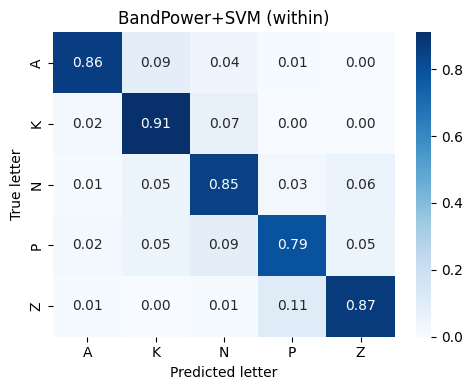

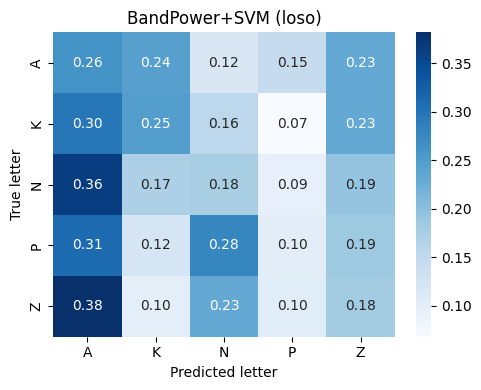

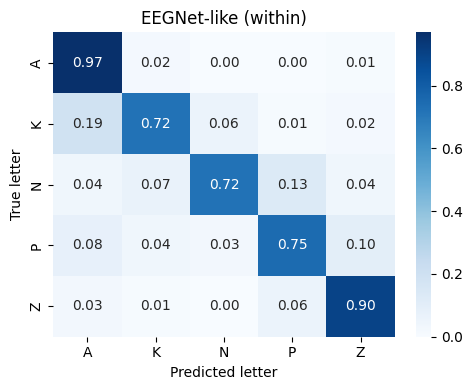

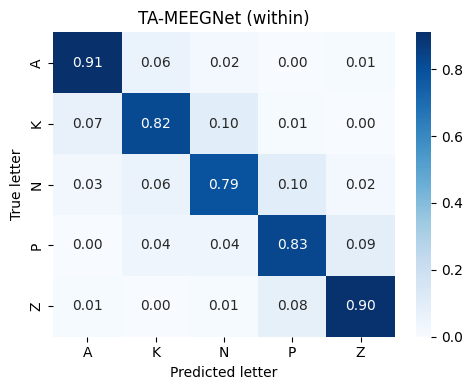

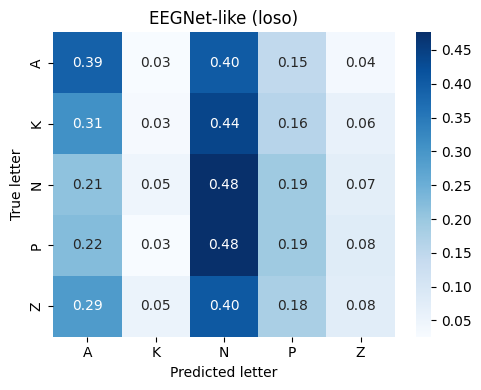

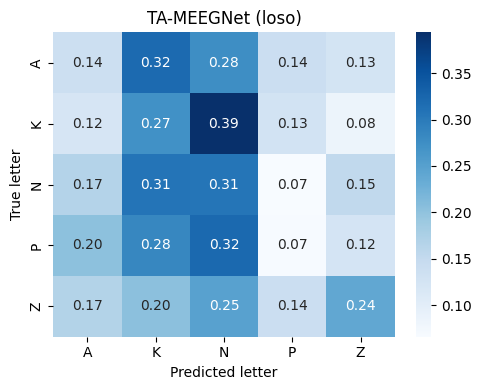

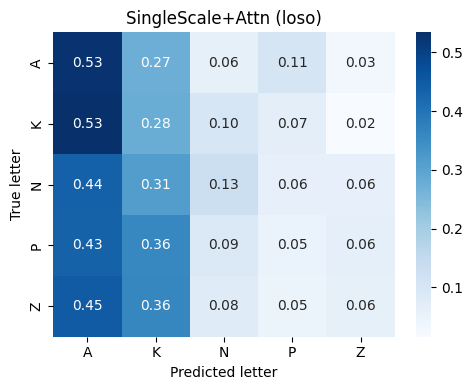

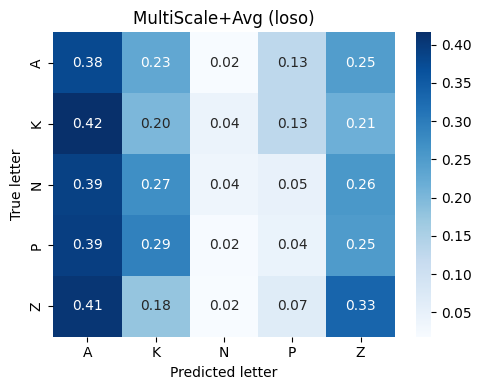

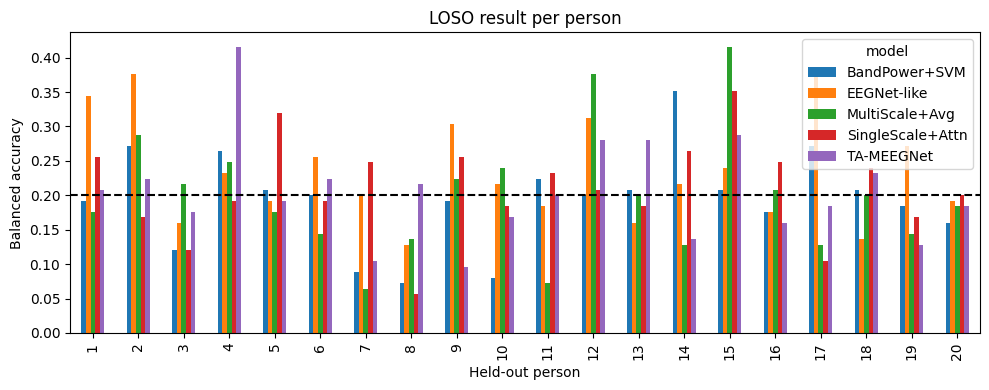

In [ ]:
import matplotlib.pyplot as plt, seaborn as sns
from scipy.stats import wilcoxon
from sklearn.metrics import confusion_matrix

def bootstrap_ci(values, n=10000, seed=0):
    rng = np.random.RandomState(seed); values = np.asarray(values)
    means = [rng.choice(values, len(values), replace=True).mean() for _ in range(n)]
    return np.percentile(means, [2.5, 97.5])

rows = []
for (name, protocol), (df, _) in ALL.items():
    lo, hi = bootstrap_ci(df['bacc'].values)
    rows.append(dict(model=name, protocol=protocol, n_people=len(df),
                     balanced_acc_mean=df.bacc.mean(), balanced_acc_sd=df.bacc.std(),
                     ci_low=lo, ci_high=hi, accuracy=df.acc.mean(), macro_f1=df.f1.mean()))
summary = pd.DataFrame(rows).round(3)
print(summary.to_string())
summary.to_csv(OUT + '/summary.csv', index=False)
pd.concat([df for df, _ in ALL.values()]).to_csv(OUT + '/per_person_results.csv', index=False)

# Paired test on LOSO results (needs the same people in both models)
def compare(a, b, protocol='loso'):
    da = ALL[(a, protocol)][0].sort_values('subject')
    db = ALL[(b, protocol)][0].sort_values('subject')
    try:
        stat, p = wilcoxon(da.bacc.values, db.bacc.values)
        print(a, 'vs', b, '| Wilcoxon p =', round(p, 4), '| mean difference =', round((da.bacc.values - db.bacc.values).mean(), 4))
    except ValueError as e:
        print('Test not possible:', e)

if ('TA-MEEGNet', 'loso') in ALL and ('EEGNet-like', 'loso') in ALL:
    compare('TA-MEEGNet', 'EEGNet-like')

# Confusion matrix for every result
def plot_confusion(name, protocol):
    df, preds = ALL[(name, protocol)]
    yt = np.concatenate([p[0] for p in preds.values()])
    yp = np.concatenate([p[1] for p in preds.values()])
    cm = confusion_matrix(yt, yp, normalize='true')
    plt.figure(figsize=(5, 4))
    sns.heatmap(cm, annot=True, fmt='.2f', cmap='Blues', xticklabels=classes, yticklabels=classes)
    plt.xlabel('Predicted letter'); plt.ylabel('True letter'); plt.title(name + ' (' + protocol + ')')
    plt.tight_layout(); plt.savefig(OUT + '/confusion_' + name + '_' + protocol + '.png', dpi=150); plt.show()

for (name, protocol) in ALL:
    plot_confusion(name, protocol)

# Per-person bars for LOSO. The dashed line is chance (0.20)
loso_df = pd.concat([df for (n, p), (df, _) in ALL.items() if p == 'loso'])
if len(loso_df):
    piv = loso_df.pivot(index='subject', columns='model', values='bacc')
    piv.index = piv.index + 1
    piv.plot(kind='bar', figsize=(10, 4))
    plt.axhline(0.2, color='black', linestyle='--'); plt.ylabel('Balanced accuracy'); plt.xlabel('Held-out person')
    plt.title('LOSO result per person'); plt.tight_layout()
    plt.savefig(OUT + '/loso_per_person.png', dpi=150); plt.show()
